In [1]:
# Window resizing
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))
display(HTML("<style>.output_result { width:90% !important; }</style>"))
display(HTML(""" <style>.output_png { display: table-cell; text-align: center; vertical-align: middle; }</style> """))
display(HTML("<style> div.text_cell_render { line-height: 2.0; } </style>"))    # Adjust linespread

# Numerical solution of a diffusion equation

In this notebook we will study the **one–dimensional diffusion (or heat) equation** under Dirichlet and Neumann boundary conditions. The equation aims to determine a function $u : (0,L) \times (0,T) \to \mathbb{R}$ such that $u(x,t)$ and its partial derivatives satisfy the following system:
<a id="eq_A"></a>
\begin{align}
    u_t - D\, u_{xx} &= 0 && \text{in } (0,L) \times (0,T), \\
    h(u,u_x,t) &= 0 && \text{on } \{0,L\} \times (0,T), \qquad\qquad\qquad\qquad(\star) \\
    u(x,0) &= I(x) && \text{in } (0,L).
\end{align}

Here, $D>0$ is the diffusion coefficient, $I: (0,L) \to \mathbb{R}$ is an initial condition, and $h: \mathbb{R}^2 \times (0,T) \to \mathbb{R}^2$ is a linear functional that can represent the boundary conditions (it uses the function, its derivative in space, and the time to output the boundary conditions). 

For instance, $h(u,u_x,t) =  \begin{pmatrix} u(0,t) - b_0, & u(L,t) - b_L \end{pmatrix}$ gives rise to (constant-in-time) inhomogeneous **Dirichlet boundary conditions**, while the choice $h(u,u_x,t) = \begin{pmatrix} u_x (0,t), & u_t(L,t) \end{pmatrix}$ represents homogeneous (zero) **Neumann conditions**.

Applying a suitable scaling in time, we can set $L = D = 1$, and we will assume so for the rest of this notebook.  Note that for the projects it will be important to determine realistic diffusion coefficients and/or timescales.

## Objectives
- Study the method of lines with the forwards (explicit) and backward (implicit) Euler methods for the diffusion equation.
- Examine the convergence and stability properties of these methods.

In [2]:
# Baseline packages
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation
from scipy.sparse        import diags_array
from scipy.sparse.linalg import spsolve
%matplotlib inline

---

# Dirichlet data

Here we are setting (constant) values at the two boundary points; ($\star$) becomes
\begin{align}
    u_t - D\, u_{xx} &= 0 && \text{in } (0,L) \times (0,T),
    \\
    u(0,t) &= b_0  && \text{in } (0,T), \qquad\qquad\qquad\qquad (\star.\mathsf{D})
    \\
    u(L,t) &= b_L  && \text{in } (0,T),
    \\
    u(x,0) &= I(x) && \text{in } [0,L].
\end{align}

We will use the method of lines to determine numerical solutions of ($\star.\mathsf{D}$) using central differences in space which transforms the partial differential equation into a system of ordinary differential equations. Here, the grid is $\big\{ m/M: m \in \{0,\ldots, M \} \big\} \subset [0,1]$, which consists of $M+1 \in \mathbb{N}$ equispaced points with separation distance $\Delta x = 1/M$. Then the ODE is given by
<a id="eq_1.a"></a>
\begin{align}
        \frac{\mathrm{d} U_m }{\mathrm{d} t} &= \frac{D}{ (\Delta x)^2 } \, ( U_{m+1} - 2 U_m + U_{m-1} )  && \text{in } (0,T), \text{for } m \in \{1, \ldots, M-1\},
        \\
        U_0 (t) &= b_0   && \text{in } (0,T),
        \\
        U_M (t) &= b_L   && \text{in } (0,T),
        \\
        U_m(0) &= I(x_m) && \text{with } x_m = m/M \text{ for } m \in \{0, \ldots, M\}.
\end{align}

You will obtain solutions for:

1. $I(x) = \sin (\pi x), b_0 =0, b_L =0 $. This has an exact solution given by the closed-form equation
\begin{align}
    u(x,t) = e^{-\pi^2 t}\sin (\pi x). \qquad\qquad\qquad\qquad (1.a)
\end{align}
\[Note that if you had a diffusion constant $D = 1$ then it would appear here -- you should be able to work out where by thinking about what time rescaling you do to eliminate $D$ and then undoing it.\]

3. $I(x) = 2.0$, $b_0 = 0$, and $b_L = 1.0$. From Q5 of Worksheet 1, there is a series representation of the solution given by 
\begin{align}
    u(x,t) =  x+ \sum_{k=1}^\infty  c_k \sin(k \pi x) \exp(-k^2 \pi^2 t)
    \qquad\text{with}\qquad
    c_k = \frac{2 (-1)^k}{k\pi} + \begin{cases} \,\,0 & \text{if $k$ is even}, \\ \dfrac{8}{k\pi} & \text{if $k$ is odd}.  \end{cases}
   \qquad\qquad\qquad\qquad (1.b)
\end{align}
Note that, here, the initial condition does not satisfy the boundary conditions and we will see some consequences of this later. (We suggest you sum up to $2\,000$ terms from the analytical solution in this case for the 'exact' solution.)

### Define boundary data and compute exact solution for comparison:

In [3]:
# For a given vector x representing the mesh of points 𝖃, define two functions I_1 and I_2 
# evaluating the initial conditions associated with (1.a) and (1.b), respectively
def I_1(x):
    ''' Computes the initial condition u(x,0) for (1.a)'''
    i_x = np.sin( np.pi * x )
    return i_x

def I_2(x):
    ''' Computes the initial condition u(x,0) for (1.b)'''
    i_x = 2.0 * np.ones_like(x) # note that ones_like produces a vector of 1's the same size as its argument
    return i_x

In [4]:
# Define two constant vectors b_1 and b_2 with the boundary data for (1.a) and (1.b), respectively
b_1 = [0.0, 0.0]    # u(0,t) = b_0, u(1,t) = b_L
b_2 = [0.0, 1.0]    # same here

In [5]:
# For a pair (x,t), where x represents the mesh of points and t is a number in [0,T], define two functions evaluating the exact solutions
def U_exact_1(x,t):
    ''' 
        Computes the exact solution u(x,t) of (1.a)
        ––––––
        Input:
            x: a numpy array discretising [0,1]
            t: a real number in [0,T]
    '''
    u_exact = np.exp(-np.pi**2 * t ) * np.sin(np.pi * x)    
    # observe that u satisfies the boundary data by definition since the sin(kpi * 0) and sin(xpi * 1) terms 
    # are zero
    
    return u_exact

def U_exact_2(x,t, K = 2000):
    ''' 
        Computes the 'exact' solution u(x,t) of (1.b)
        ––––––
        Input:
            x: a numpy array discretising [0,1]
            t: a real number in [0,T]
            K: number of Fourier coefficients
    '''

    # Start with the x term
    u_exact = x.copy()  # make sure you use .copy, otherwise changes to u_exact also apply to x!

    # Loop to add in each k-dependent term
    for k in range(1,K):
        kpi= k*np.pi
        c_k = 2*(-1)**k/kpi;
        if k%2 == 1:  # deal with the k is odd case
            c_k += 8/kpi
        u_exact += c_k * np.sin(kpi * x) * np.exp( -1 * kpi**2 * t)

    # observe that u satisfies the boundary data by definition since the sin(kpi * 0) and sin(xpi * 1) terms 
    # are zero and x satisfies the boundary condition
    
    return u_exact

## Forward Euler method

We discretise the time dimension using forward differences in ($1a,b$) using the mesh $\big\{ n/N:  n \in \{0,\ldots,N\} \big\}$ of $N+1 \in \mathbb{N}$ points equispaced by $\Delta t = 1/N$. Then, we obtain the difference system:
\begin{align}
        \frac{1}{\Delta t} (U_m^{n+1} - U_m^n) &= \frac{1}{ (\Delta x)^2 } \, ( U_{m+1}^n - 2 U_m^n + U_{m-1}^n )  && \text{for } m \in \{1, \ldots, M-1\},  n \in \{1, \ldots, N-1\},
        \\
        U_0^n &= b_0  &&  \text{for } n \in \{1, \ldots, N-1\},
        \\
        U_M^n &= b_L  &&  \text{for } n \in \{1, \ldots, N-1\}, \qquad\qquad\qquad\qquad (2.a)
        \\
        U_m^0 &= I(x_m) && \text{for } m \in \{0, \ldots, M\}.
\end{align}

where now $U_m^n$ is the fully discrete approximation of $U \left( x = x_m = m \Delta x, t = t_n = n \Delta t \right)$.

🚩 **Using the script below, complete this discretisation of the initial boundary value problem. Run your code for $N = 20,000$, $T = 1.0$, and $M =100 $. Discuss what is happening to temperature/density distribution and the causes of any differences between the analytic and numerical solutions.**

### Solve difference equations:

In [6]:
# ** Set parameters ** #
N = 20000    # number of timesteps
T = 1.0      # final time 
t = np.linspace(0.0, T, N + 1)      # Time grid

M = 100    # number of spaces in x
x = np.linspace(0.0, 1.0, M + 1)    # Space grid

dx = x[1] - x[0] # step sizes
dt = t[1] - t[0]

C = dt/(dx**2) # stability condition
print('dx = {0:.2e}, dt = {1:.2e}, C = {2}'.format(dx, dt, C))

dx = 1.00e-02, dt = 5.00e-05, C = 0.5


#### Solution to ($1.a$)

In [7]:
# ** Initialize output ** #

# Preallocate the numerical solution in a matrix: the first dimension is time and the second is space; 
# i.e., each row corresponds to a timestep
U = np.zeros((N+1,M+1))

# Set the initial condition
U[0] = I_1(x) 
# Enforce boundary conditions for all space points (including overwriting the initial condition)
# You may want to investigate what happens if you don't overwrite the boundary conditions for the IC
U[:,[0,-1]] = b_1

# ** Iterate ** #
for n in range(0, N):
    # Python is optimised for the use of slices, se we can just select the indices where the update occurs:
    #   - U[n, :]       is U at timestep n
    #   - U[n, 1:-1]    is U at timestep n inside the spatial interval (0,1) [without {0,1}]
    #   - U[n, :-2]     contains all points in [0,1) except the last one
    #   - U[n, 2:]      contains all points in (0,1] except the first one
    # note that we do not update the boundary terms as they are constant in time
    U[n+1,1:-1] = U[n,1:-1] + C * ( U[n,:-2] - 2 * U[n,1:-1] + U[n,2:] )

In [8]:
# ** Set up a plotting function ** #

def plotting(U,x,t, exact_handle = U_exact_1):
    # Set some markers and colours to make comparison easy
    markers = ['x','s','d','+','o','.']
    colours = ['xkcd:salmon','xkcd:golden rod','xkcd:teal','xkcd:purple','xkcd:slate','xkcd:silver']    
    
    # choose some (almost arbitrary) display times
    disp_times = [0, N//20, N//10, N//5, N//2, N]              

    # Set up the figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))

    # Dummy plot for legend titles
    ax.scatter([0], [0], color='white', label=r'Exact $u(x,t)$', lw=0)

    # Plot actual curves
    for i, idx_t in enumerate(disp_times):
        label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < T) else 't = {0:.0f}'.format(t[idx_t])
        ax.plot(x, exact_handle(x,t[idx_t]), color = colours[i], label = label)

    ax.scatter([0], [0], color='white', label=r'Numerical $U(x,t)$', lw=0)
    for i, idx_t in enumerate(disp_times):
        label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < T) else 't = {0:.0f}'.format(t[idx_t])
        ax.plot(x[::2], U[idx_t][::2], linestyle = '', marker = markers[i], color = colours[i], label = label )

    ax.legend(ncols = 2, loc = 'center',  bbox_to_anchor=(1.2, 0.5), title ='Comparison')
    ax.set_xlim(0-1e-2,1.0+1e-2)    # zoom in on area of interest with a bit of leeway each end
    plt.xlabel("Space (x)")
    plt.ylabel("Solution")
    plt.show()

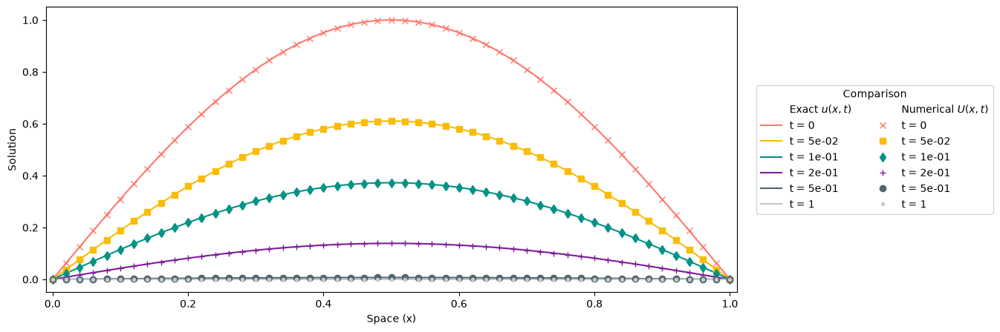

In [9]:
plotting(U,x,t, U_exact_1)

#### Solution to ($1.b$)

In [10]:
# ** Initialize output ** #

# Preallocate the numerical solution in a matrix: the first dimension is time and the second is space; 
# i.e., each row corresponds to a timestep
U = np.zeros((N+1,M+1))

# Set the initial condition
U[0] = I_2(x)
# Enforce boundary conditions for all space points (including overwriting the initial condition)
U[:,[0,-1]] = b_2

# ** Iterate ** #
for n in range(0, N):
    # Python is optimised for the use of slices, se we can just select the indices where the update occurs:
    #   - U[n]          is U at timestep n
    #   - U[n, 1:-1]    is U inside (0,1) [without {0,1}]
    #   - U[n,  :-2]    contains all points in [0,1) except the last one
    #   - U[n, 2:]      contains all points in (0,1] except the first one
    #
    U[n+1,1:-1] = U[n,1:-1] + C * ( U[n,:-2] - 2 * U[n,1:-1] + U[n,2:] )

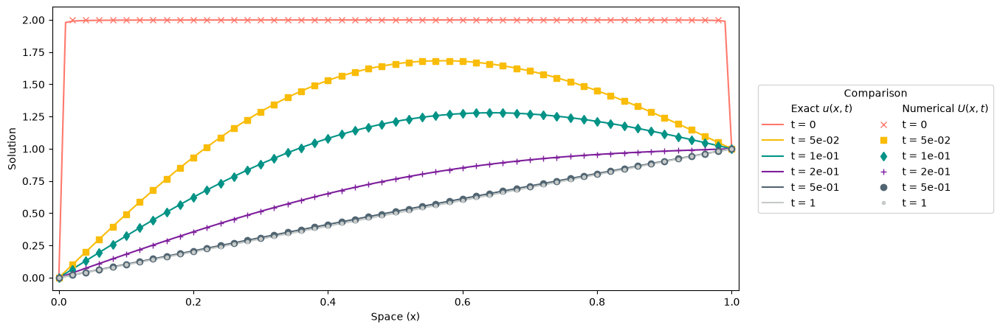

In [11]:
plotting(U,x,t, U_exact_2)

You should see the exact solution match the numerical solution at all displayed times for the two choices of initial condition. You may want to investigate what happens for early (positive) times and think about the cause of any differences.

🚩**Run the script with different (positive) values of $\Delta t$. For which values of $\Delta t$ is the scheme stable?** 

(Hint: the condition required for stability is in the form $\Delta t / (\Delta x)^2 \leq C$, for some constant $C > 0$. What is the value of $C$?)

**Solution:** The scheme is stable provided $\Delta t / (\Delta x)^2 \leq 0.5$. To see that numerically, we can change parameters such as $N$ slightly. We can see that when $C$ is slightly over $0.5$ (say, at $0.55$), the solution would overflow after a few time steps. 

## Backward Euler method


In this part, you should try to implement the Backward Euler method for the diffusion equation. This involves replacing the Forward Euler scheme with
<a id="eq_3.a"></a>

\begin{align}
        \frac{1}{\Delta t} (U_m^{n+1} - U_m^n) &= \frac{1}{ (\Delta x)^2 } \, ( U_{m+1}^{n+1} - 2 U_m^{n+1} + U_{m-1}^{n+1} )  && \text{for } m \in \{1, \ldots, M-1\},  n \in \{1, \ldots, N-1\},
        \\
        U_0^n &= b_0  &&  \text{for } n \in \{1, \ldots, N-1\},
        \\
        U_M^n &= b_L  &&  \text{for } n \in \{1, \ldots, N-1\}, \qquad\qquad\qquad\qquad (3.a)
        \\
        U_m^0 &= I(x_m) && \text{for } m \in \{0, \ldots, M\}.
\end{align}

Consider the same initial and boundary conditions as in the previous part.

🚩 **Using the script below, complete the backward Euler discretisation of the initial boundary value problem, with $M = 200$, $T = 1$, and $N = 100$.**

### Define discretisation matrix

In [12]:
# ** Set parameters ** #
N = 200      # number of timesteps
T = 1.0      # final time 
t = np.linspace(0.0, T, N + 1)      # Time grid

M = 100    # number of spaces in x
x = np.linspace(0.0, 1.0, M + 1)    # Space grid

dx = x[1] - x[0] # step sizes
dt = t[1] - t[0]

C = dt/(dx**2)
print('dx = {0:.2e}, dt = {1:.2e}, C = {2}'.format(dx, dt, C))

dx = 1.00e-02, dt = 5.00e-03, C = 50.0


In [13]:
# Store data in sparse format to prevent the memory allocation of M² - M + 2 zeros

# Values on the three non-zero diagonals
diags = np.ones((3,M+1))

# Add 2C to main diagonal except at the endpoints (first index = 0 represents the main diagonal here)
diags[0,1:-1] += 2 * C             

# The upper and lower diagonals are -C except in the first/last row, which we will deal with next
diags[1:] = - C;    

# Fix the upper diagonal in the first row (the first entry should be zero)
diags[1,0] = 0.0

# Fix the lower diagonal in the last row (the penultimate entry should be zero - the last is ignored when making A)
diags[2,-2] = 0.0 

# Create the matrix, taking care of the order in which we defined the diagonals
# format = 'csr' defines a sparse matrix
A = diags_array(diags, offsets = (0,1,-1), shape = (M+1, M+1), format = 'csr')

# Alternative method using a for loop
# Note that this doesn't make a sparse matrix
# B = np.zeros((M+1, M+1))

# for i in range(1, M):
#     B[i,i-1] = -C
#     B[i,i+1] = -C
#     B[i,i] = 1 + 2*C
    
# # set the Dirichlet conditions
# B[0,0] = 1
# B[M,M] = 1

### Solve system

#### Solution to ($1.a$)

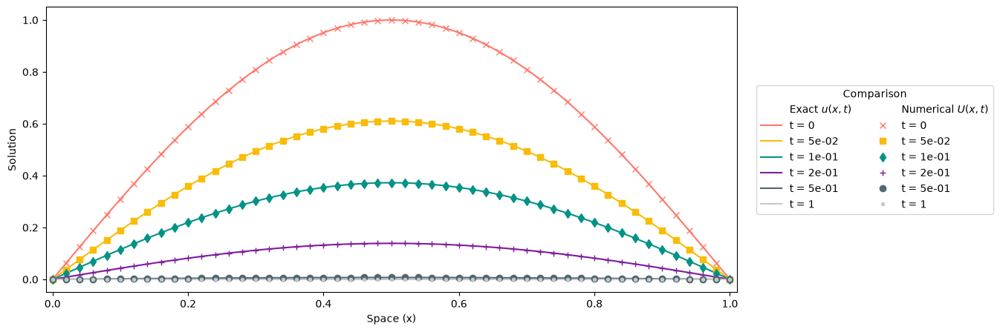

In [14]:
# ** Initialize output ** #

# Preallocate the numerical solution in a matrix: 
# the first dimension is time and the second is space; i.e., each row corresponds to a timestep
U = np.zeros((N+1,M+1))
U[0] = I_1(x)
# Enforce boundary conditions for all space points
U[:,[0,-1]] = b_1

# Also store exact solution
U_ex = np.zeros((N+1,M+1))

# ** Iterate ** #
for n in range(0, N):
    # Solve linear system instead of computing the inverse: 
    # computing the inverse is expensive and numerically instable 
    # SciPy has a subroutine for sparse matrices, but if you want to stick to NumPy, 
    # you can instead use: np.linalg.solve(A.toarray(),U[n])
    U[n+1] = spsolve(A, U[n])
    U_ex[n] = U_exact_1(x,t[n])

# Feel free to compare the solution as before:
plotting(U_ex,x,t, U_exact_1)

In [15]:
# set up animation plots (this may take a few seconds to run)
def animate(i):
    l.set_data(x, U[i])
    m.set_data(x[::2],U_ex[i][::2])
    return l,m

fig, ax = plt.subplots()
ax.axis([0.0-1e-2, 1+1e-2, 0.0-1e-2, U_ex.max()+1e-2])
l, = ax.plot([],[],'-', color = 'xkcd:slate', linewidth=2)
m, = ax.plot([],[],'', color = 'xkcd:salmon', marker = 'x')
ani = matplotlib.animation.FuncAnimation(fig, animate, interval=50, frames = N+1, blit=True)
# Close the figure so it doesn't display the static plot
plt.close(fig)
# Display animation
HTML(ani.to_jshtml())

#### Solution to ($1.b$)

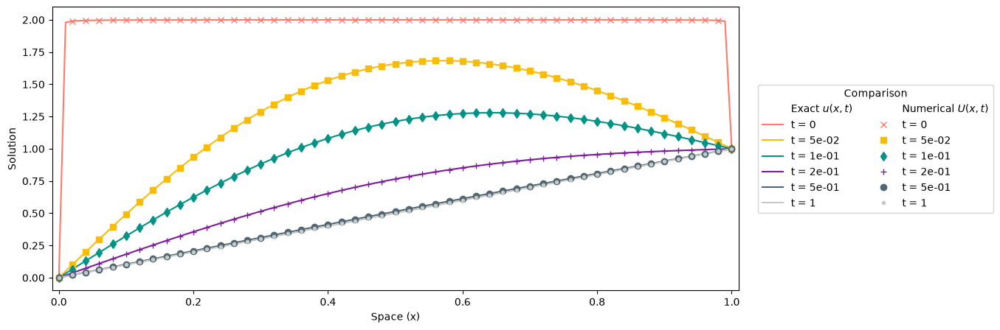

In [16]:
# ** Initialize output ** #

# Preallocate the numerical solution in a matrix: the first dimension is time and the second is space; i.e., each row corresponds to a timestep
U = np.zeros((N+1,M+1))
U[0] = I_2(x)
# Enforce boundary conditions for all space points
U[:,[0,-1]] = b_2

# Also store numerical solution
U_ex = np.zeros((N+1,M+1))

# ** Iterate ** #
for n in range(0, N):
    # Solve linear system instead of computing the inverse: computing the inverse is expensive and numerically instable 
    # SciPy has a subroutine for sparse matrices, but if you want to stick to NumPy, you can instead use: np.linalg.solve(A.toarray(),U[0])
    U[n+1] = spsolve(A, U[n])
    U_ex[n] = U_exact_2(x,t[n])
U_ex[n+1] = U_exact_2(x,t[n+1])

# Feel free to compare the solution as before:
plotting(U_ex,x,t, U_exact_2)

In [17]:
# set up animation plots (this may take a few seconds to run)
def animate(i):
    l.set_data(x, U[i])
    m.set_data(x[::2],U_ex[i][::2])
    return l,m

fig, ax = plt.subplots()
ax.axis([0.0-1e-2, 1+1e-2, 0.0-1e-2, U_ex.max()+1e-2])
l, = ax.plot([],[],'-', color = 'xkcd:slate', linewidth=2)
m, = ax.plot([],[],'--', color = 'xkcd:salmon', marker = 'x')
ani = matplotlib.animation.FuncAnimation(fig, animate, interval=50, frames = N+1, blit=True)
# Close the figure so it doesn't display the static plot
plt.close(fig)
# Display animation
HTML(ani.to_jshtml())

---

# Neumann data

Here we set the derivative of the solution to be zero at both endpoints; ($\star$) becomes
\begin{align}
    u_t - D\, u_{xx} &= 0 && \text{in } (0,L) \times (0,T),
    \\
    u_x(0,t) = u_x(L,t) &= 0  && \text{in } (0,T), \qquad\qquad\qquad\qquad (\star.\mathsf{N})
    \\
    u(x,0) &= I(x) && \text{in } [0,L].
\end{align}

In this part, you should try to implement the Backward Euler method for the diffusion equation with zero Neumann boundary conditions ($\star.\mathsf{N}$). This involves replacing the space derivatives $u_x(0,t) = u_x(1,t) = 0$ with a central order approximation that yields
\begin{align}
        U_m^{n+1} &= U_m^n + \underbrace{ \frac{\Delta t}{ (\Delta x)^2 } }_{C} \, ( U_{m+1}^{n+1} - 2 U_m^{n+1} + U_{m-1}^{n+1} )  && \text{for } m \in \{1, \ldots, M-1\},  n \in \{1, \ldots, N-1\},
        \\
        U_0^n &= -2 C U_1^{n+1} + (1+2C) U_0^{n+1}  &&  \text{for } n \in \{1, \ldots, N-1\},
        \\
        U_M^n &= -2 C U_{M-1}^{n+1} + (1+2C) U_M^{n+1}  &&  \text{for } n \in \{1, \ldots, N-1\}, \qquad\qquad\qquad\qquad (4.a)
        \\
        U_m^0 &= I(x_m) && \text{for } m \in \{0, \ldots, M\}.
\end{align}

Thus the matrix for backward differences with Euler data is a modification of the matrix associated with Dirichlet data in the first and last rows. 

Now try solving the equation with the initial data $I(x) = x$. The solution of ($\star.\mathsf{N}$) is given, once more, as a Fourier series which was found in Q6 of Worksheet 1:
<a id="eq_4.b"></a>
\begin{align}
    u(x,t) =  \frac{1}{2} + \sum_{k=1}^\infty  c_k \cos(k \pi x) \exp(-k^2 \pi^2 t)
    \qquad\text{with}\qquad
    c_k = \begin{cases} \,\,0 & \text{if $k$ is even}, \\ -\dfrac{4}{(k\pi)^2} & \text{if $k$ is odd}.  \end{cases}
    \qquad\qquad\qquad\qquad (4.b)
\end{align}

In [18]:
# ** Initial condition ** #
def I(x):    return x

# ** Exact solution ** #
def U_exact(x,t, K = 2000):
    ''' 
        Computes the 'exact' solution u(x,t) of (4.b)
        ––––––
        Input:
            x: a numpy array discretising [0,1]
            t: a real number in [0,T]
            K: number of nonzero Fourier coefficients
    '''

    # start with the constant part
    u_exact = 0.5*np.ones_like(x)
        
    # ** Sum K terms of the Fourier representation **
    # Note that we only need to include the even terms
    for k in range(1,K,2):
        kpi= k*np.pi
        c_k = -(4.0)/(kpi**2)
        u_exact = u_exact + c_k * np.cos(kpi*x) * np.exp(-1 * kpi**2 * t)
    
    return u_exact

### Define discretisation matrix

In [19]:
# ** Set parameters ** #
N = 200      # number of timesteps
T = 1.0      # final time 
t = np.linspace(0.0, T, N + 1)      # Time grid

M = 100    # number of spaces in x
x = np.linspace(0.0, 1.0, M + 1)    # Space grid

dx = x[1] - x[0] 
dt = t[1] - t[0]

C = dt/(dx**2)
print('dx = {0:.2e}, dt = {1:.2e}, C = {2}'.format(dx, dt, C))

dx = 1.00e-02, dt = 5.00e-03, C = 50.0


In [20]:
# Store data in sparse format to prevent the memory allocation of M² - M + 2 zeros

# Values on the three non-zero diagonals
diags = np.ones((3,M+1))

# Add 2C to main diagonal (first index = 0 represents the main diagonal here)
diags[0] += 2 * C             

# The upper and lower diagonals are -C except in the first/last row, which we will deal with next
diags[1:] = - C;    

# Fix the upper diagonal in the first row (the first entry should be -2C)
diags[1,0] = - 2*C

# Fix the lower diagonal in the last row (the penultimate entry should be -2C - the last is ignored when making A)
diags[2,-2] = -2*C

# Create the matrix, taking care of the order in which we defined the diagonals
# format = 'csr' defines a sparse matrix
A = diags_array(diags, offsets = (0,1,-1), shape = (M+1, M+1), format = 'csr')


### Solve system

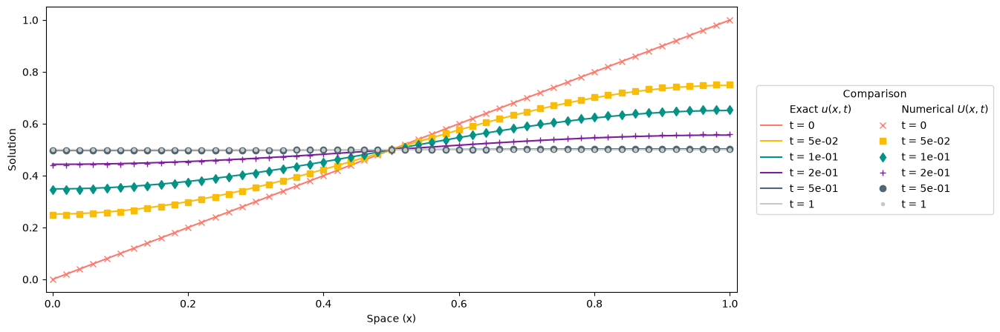

In [21]:
# ** Initialize output ** #

# Preallocate the numerical solution in a matrix: the first dimension is time and the second is space; i.e., each row corresponds to a timestep
U = np.zeros((N+1,M+1))
U[0] = I(x)

# Also store numerical solution
U_ex = np.zeros((N+1,M+1))

# ** Iterate ** #
for n in range(0, N):
    # Solve linear system instead of computing the inverse: computing the inverse is expensive and numerically instable 
    # SciPy has a subroutine for sparse matrices, but if you want to stick to NumPy, you can instead use: np.linalg.solve(A.toarray(),U[0])
    U[n+1] = spsolve(A, U[n])
    U_ex[n] = U_exact(x,t[n])
    
U_ex[n+1] = U_exact(x,t[n+1])

# Feel free to compare the solution as in the first bit of the notebook:
plotting(U,x,t, U_exact)

In [22]:
# set up animation plots (this may take a few seconds to run)
def animate(i):
    l.set_data(x, U[i])
    m.set_data(x[::2],U_ex[i][::2])
    return l,m

fig, ax = plt.subplots()
ax.axis([0.0-1e-2, 1+1e-2, 0.0-1e-2, U_ex.max()+1e-2])
l, = ax.plot([],[],'-', color = 'xkcd:slate', linewidth=2)
m, = ax.plot([],[],'--', color = 'xkcd:salmon', marker = 'x')
ani = matplotlib.animation.FuncAnimation(fig, animate, interval=50, frames = N+1, blit=True)
# Close the figure so it doesn't display the static plot
plt.close(fig)
# Display animation
HTML(ani.to_jshtml())

---